# Bent Waveguide -- Meep Baseline, Radius Sweep, and Circular-vs-Euler Comparison

Second component in the toolkit. A **circular arc** bend
(`gf.components.bend_circular`) and a **Euler (clothoid) bend**
(`gf.components.bend_euler`) of the same nominal radius are genuinely different
shapes: an Euler bend's curvature ramps smoothly from zero up to `1/radius_um`,
instead of jumping abruptly there the way a circular arc does at its tangent
points. That abrupt discontinuity is what causes extra mode-mismatch loss in a
circular bend, so a Euler bend is expected to show **lower bending loss at the
same radius** -- this notebook measures that directly.

Same sections as the waveguide notebook:
1. **Component definition** -- global parameters.
2. **GDSFactory geometry** -- build both bend types as gdsfactory `Component`s.
3. **Geometry visualization** -- layout + permittivity map for both bend types.
4. **2D Meep FDTD simulation** -- baseline run, radius sweep, field visualization,
   S-parameters, and a bending-loss plot.
5. **SAX model fitting** -- fit insertion loss and phase vs. `radius_um`, separately
   per bend type, into `models/bend.py`.

**Do not use "Run All."** Work through the notebook step by step, and stop at
the marked checkpoints to actually look at the plots before continuing.

## 1. Component definition -- Global Parameters

**Governing relations.** A bend of radius $R$ adds loss beyond the straight
waveguide's own propagation loss, from two mechanisms: **transition
(mode-mismatch) loss** at the straight-to-bend junction, and **radiation loss**
from the guided mode's evanescent tail no longer being able to keep up with the
mode's curved wavefront once the local radius of curvature is too tight.
Radiation loss falls off steeply and roughly exponentially with radius, so a
standard empirical form is
$$\mathrm{Loss}_{dB}(R) = \mathrm{Loss}_{dB,\infty} + A\, e^{-R/R_0},$$
a floor term (large-radius loss, dominated by transition/propagation loss and
largely radius-independent) plus a term decaying over a characteristic radius
$R_0$. Section 5 fits exactly this functional form to the radius sweep below.

In [1]:
import inspect
import json

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import gdsfactory as gf

from pic_toolkit.params import GLOBAL_PARAMS
from pic_toolkit.meep_sim import bend
from pic_toolkit import checks, viz, sparams, design_points, sweep, style

style.apply_style()
%matplotlib inline

In [2]:
# GLOBAL_PARAMS (shared across every component) + this component's own extras.
params = dict(bend.DEFAULT_PARAMS)

print("Global Parameters (from pic_toolkit.params.GLOBAL_PARAMS)")
print(f"  waveguide width      : {params['wg_width_um']} um")
print(f"  core / clad index    : {params['core_index']} / {params['clad_index']}")
print(f"  polarization         : {params['polarization']}")
print(f"  wavelength band      : {params['wl_min_um']}-{params['wl_max_um']} um")
print()
print("Component-specific parameters (meep_sim/bend.py's own DEFAULT_PARAMS)")
print(f"  resolution           : {params['resolution']} px/um  (finer than the toolkit-wide")
print(f"                          default, chosen from a resolution-convergence study)")
print(f"  representative radius: {params['radius_um']} um")
print(f"  arm length           : {params['arm_length_um']} um")
print(f"  bend type            : {params['bend_type']}")


Global Parameters (from pic_toolkit.params.GLOBAL_PARAMS)
  waveguide width      : 0.5 um
  core / clad index    : 2.7 / 1.44
  polarization         : TE
  wavelength band      : 1.3-1.4 um

Component-specific parameters (meep_sim/bend.py's own DEFAULT_PARAMS)
  resolution           : 40 px/um  (finer than the toolkit-wide
                          default, chosen from a resolution-convergence study)
  representative radius: 2.0 um
  arm length           : 3.0 um
  bend type            : circular


## 2. GDSFactory geometry

`build_gf_component(params)` builds the bend as `gf.components.bend_circular`
or `gf.components.bend_euler` (`params["bend_type"]`), each with a
`arm_length_um`-long straight lead on both ports, connected via
`ComponentReference.connect()`. Both bend types are built once here, at the
representative radius, for a direct visual comparison in Section 3.

In [3]:
# Print the actual builder function's source -- see its docstring for the
# gdsfactory-to-native coordinate-frame alignment details.
print(inspect.getsource(bend.build_gf_component))


def build_gf_component(params: dict):
    """Build the bend + two straight arms as a gdsfactory Component. Ports o1
    (horizontal arm, facing -x, light travels +x into the bend) and o2
    (vertical arm, facing +y, light exits +y) come from gf.components.
    bend_circular or bend_euler (params["bend_type"]) at the given radius_um,
    angle=90, connected to two arm_length_um-long gf.components.straight()
    leads via ComponentReference.connect().

    gdsfactory's bend has its horizontal tangent point (o1) at the origin and
    its arc/turn center at (0, radius_um) -- offset by (-radius_um, 0) from
    this module's native (unshifted) convention (arc center at
    (-radius_um, radius_um), see _domain()'s docstring), which itself is then
    translated by _domain()'s own `shift` to land in the tight, asymmetric
    cell. Combining both -- `(-radius_um + shift.x, shift.y)` below -- makes
    gdsfactory's geometry coincide exactly with `_domain()`/`_port_planes()`'s
    (shifted) coor

In [4]:
# Build both bend types at the SAME representative radius, for a direct
# visual comparison in Section 3 -- confirm their bounding boxes/ports agree
# (same footprint, same port locations) before simulating either.
gf_circular = bend.build_gf_component({**params, "bend_type": "circular"})
gf_euler = bend.build_gf_component({**params, "bend_type": "euler"})

for name, c in [("circular", gf_circular), ("euler", gf_euler)]:
    print(f"{name}: bbox (um) = {c.dbbox()}")
    for p in c.ports:
        print(f"  port {p.name}: center={tuple(p.dcenter)} um, orientation={p.orientation} deg")


circular: bbox (um) = (-2.625,-2.625;2.625,2.625)
  port o1: center=(-2.625, -2.375) um, orientation=180.0 deg
  port o2: center=(2.375, 2.625) um, orientation=90.0 deg
euler: bbox (um) = (-2.625,-2.625;2.625,2.625)
  port o1: center=(-2.625, -2.375) um, orientation=180.0 deg
  port o2: center=(2.375, 2.625) um, orientation=90.0 deg


## 3. Geometry visualization

Raw gdsfactory layouts, both bend types at the representative radius, side by
side.

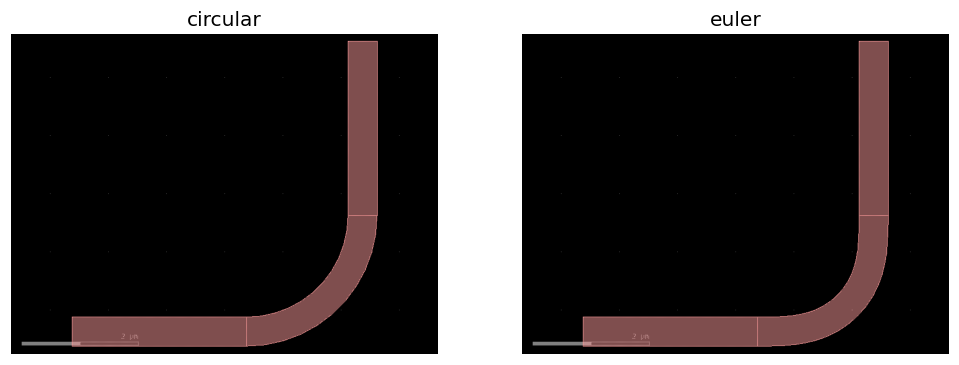

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, name, c in [(axes[0], "circular", gf_circular), (axes[1], "euler", gf_euler)]:
    fig_c = c.plot(return_fig=True)
    ax.imshow(fig_c.axes[0].images[0].get_array())
    ax.set_title(name)
    ax.axis("off")
    plt.close(fig_c)
plt.show()

Meep permittivity maps: the gdsfactory-sourced circular bend against the
**native** `build_geometry()` (a true, analytically-defined circular arc,
built independently of gdsfactory) -- and the gdsfactory-sourced Euler bend,
which is expected to differ from both, not just by discretization noise.

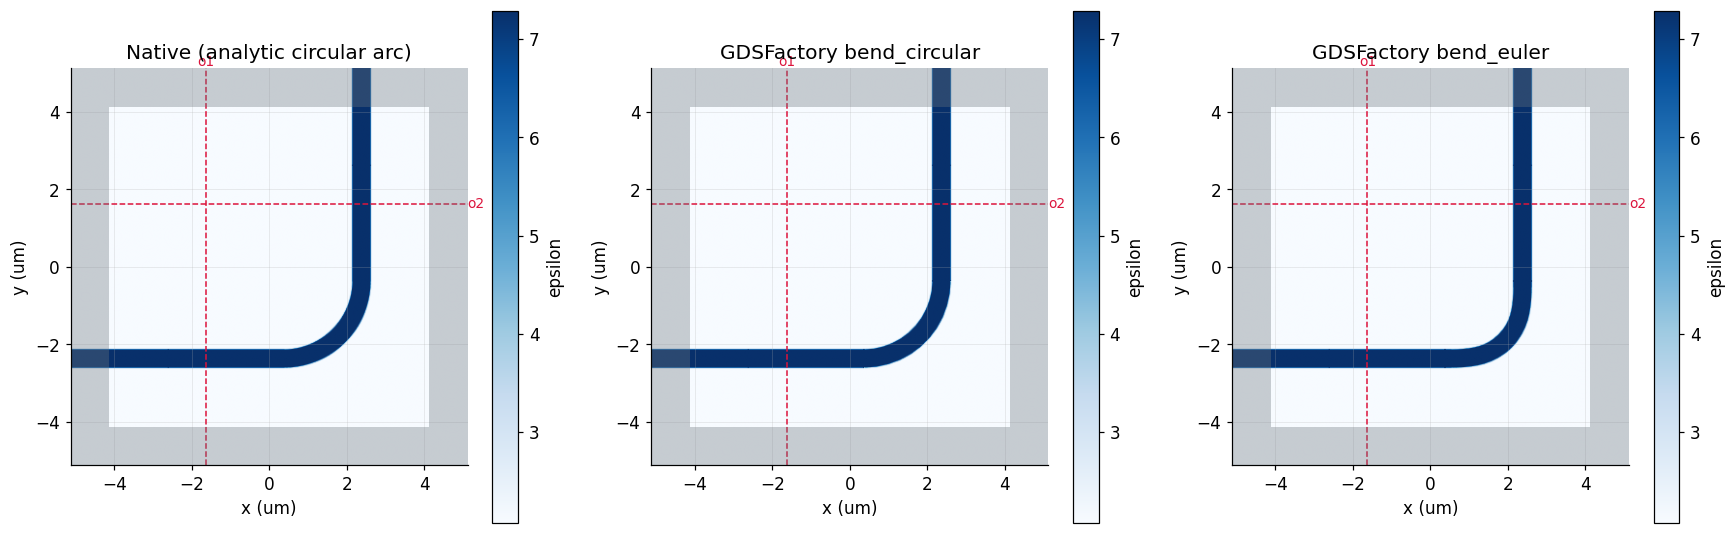

max |native - gds_circular| eps difference: 1.251  (small -- ordinary polygon-discretization boundary noise between two
                                              independently-built representations of the same arc)
max |native - gds_euler|    eps difference: 5.216  (large -- a genuinely different curvature profile, not noise)


In [6]:
# Three permittivity maps, side by side: the native analytic circular arc,
# the gdsfactory circular bend (should match the native one almost exactly),
# and the gdsfactory Euler bend (expected to genuinely differ -- see markdown
# below). None of this runs any FDTD timestepping -- cheap to compute.
def ports_for(p):
    p1c, p1s, p2c, p2s = bend._port_planes(p)
    return [(p1c.x, p1c.y, "o1", "v"), (p2c.x, p2c.y, "o2", "h")]

perm_native = bend.get_permittivity_map(params, use_native_geometry=True)
perm_gds_circular = bend.get_permittivity_map({**params, "bend_type": "circular"}, use_native_geometry=False)
perm_gds_euler = bend.get_permittivity_map({**params, "bend_type": "euler"}, use_native_geometry=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
viz.plot_permittivity(perm_native.eps, perm_native.extent_um, ax=axes[0], ports=ports_for(params), pml_um=params["dpml_um"])
axes[0].set_title("Native (analytic circular arc)")
viz.plot_permittivity(perm_gds_circular.eps, perm_gds_circular.extent_um, ax=axes[1], ports=ports_for(params), pml_um=params["dpml_um"])
axes[1].set_title("GDSFactory bend_circular")
viz.plot_permittivity(perm_gds_euler.eps, perm_gds_euler.extent_um, ax=axes[2], ports=ports_for(params), pml_um=params["dpml_um"])
axes[2].set_title("GDSFactory bend_euler")
fig.tight_layout()
plt.show()

# Quantify the two comparisons printed below the figure: circular-vs-native
# should be near-zero (same shape, different discretization); euler-vs-native
# should be large (genuinely different curvature profile).
diff_circular = np.abs(perm_native.eps - perm_gds_circular.eps)
diff_euler = np.abs(perm_native.eps - perm_gds_euler.eps)
print(f"max |native - gds_circular| eps difference: {diff_circular.max():.3f}  "
      f"(small -- ordinary polygon-discretization boundary noise between two")
print(f"                                              independently-built representations of the same arc)")
print(f"max |native - gds_euler|    eps difference: {diff_euler.max():.3f}  "
      f"(large -- a genuinely different curvature profile, not noise)")


The circular-vs-native difference is a small fraction of a full core/clad
epsilon swing -- ordinary boundary-pixel disagreement between two independently
discretized representations of the same continuous arc. The Euler-vs-native
difference is much larger -- confirming the Euler bend really is a different
shape, not just a different polygon approximation of the same circle.

**Domain size**: the simulation cell is a tight, asymmetric box around the
L-shaped structure, not a symmetric square with a wasted empty quadrant (see
`meep_sim/bend.py`'s `_domain()`). The dashed red lines mark the `o1`/`o2` port
reference planes and the shaded gray band is the PML. In the FDTD runs both arms also
continue straight through the cladding margin and the PML to the cell edge
(`bend._lead_extensions`, not part of the exported component): an arm ending in the
margin would be a cleaved facet with ~6 % Fresnel reflection inside the measured
S-matrix.

> **STOP -- inspect all three permittivity maps before running any FDTD.**
>
> Check: is the core centered, the right width, and fully surrounded by
> cladding in every panel? Do the circular-native and circular-gdsfactory
> panels look essentially identical? Do the `o1`/`o2` port lines sit on the
> straight arms, clear of the curved section, with visible PML clearance
> beyond them?

## 4. 2D Meep FDTD simulation

### 4.1-4.2 Baseline runs (representative radius, both bend types)

`simulate_baseline()` defaults to the gdsfactory-sourced geometry. Run once
per bend type at the representative radius.

In [7]:
# Full two-port characterization, once per bend type, at the representative
# radius -- each call excites o1 then o2 independently to measure the
# complete 2x2 S-matrix.
results = {}
for bend_type in ["circular", "euler"]:
    r = bend.simulate_baseline({**params, "bend_type": bend_type})
    results[bend_type] = r
    print(f"{bend_type}: {len(r.wavelengths_um)} wavelength points, "
          f"{r.wavelengths_um.min():.4f}-{r.wavelengths_um.max():.4f} um")


circular: 21 wavelength points, 1.3017-1.4020 um


euler: 21 wavelength points, 1.3017-1.4020 um


### 4.3 Electromagnetic field visualization -- polarization convention

Both bend types are simulated in the TE polarization (Section 1). In Meep's 2D
convention, TE's dominant out-of-plane field component is `Hz`, not `Ez` --
both are captured below and whichever actually dominates is reported, so the
result is confirmed by direct measurement rather than assumed.

circular: dominant field component = Hz
euler: dominant field component = Hz


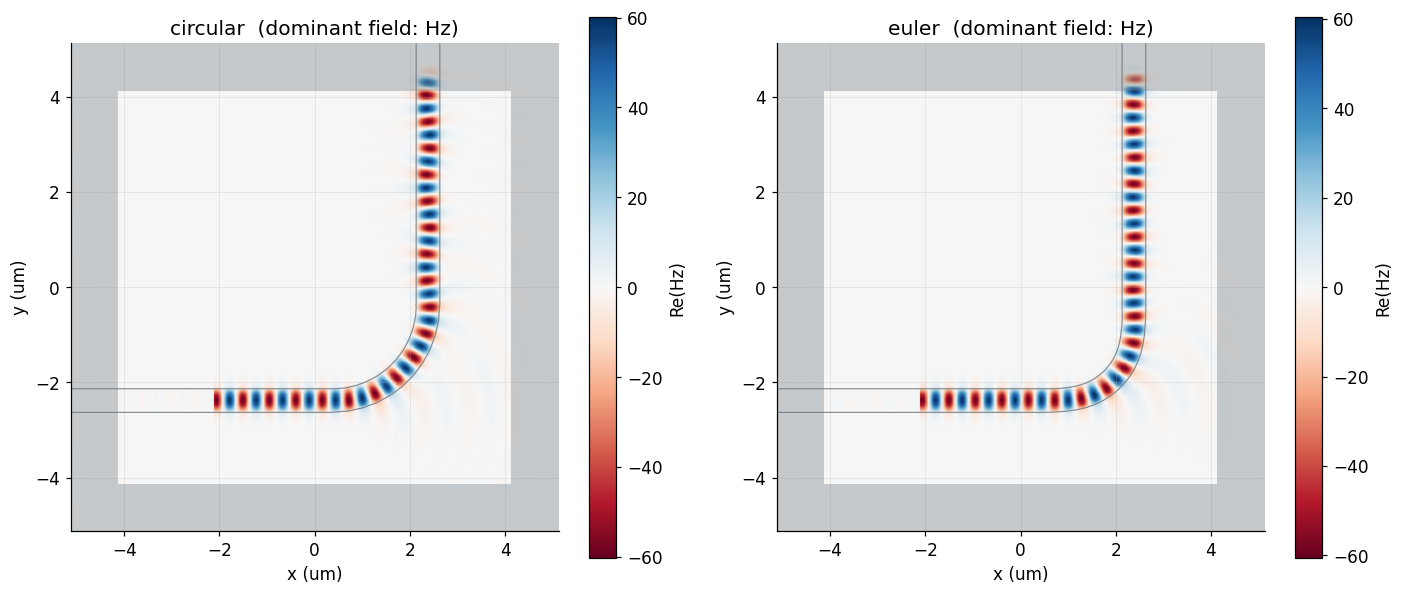

In [8]:
# Plot whichever field component (Ez or Hz) actually dominates for each bend
# type, side by side -- watch for a visibly different amount of radiation
# leaking into the cladding at the outer wall of the turn (see markdown below).
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, bend_type in zip(axes, ["circular", "euler"]):
    fs = results[bend_type].field_snapshot
    viz.plot_field(fs.field, fs.eps, fs.extent_um, component=fs.component, ax=ax,
                    pml_um=params["dpml_um"])
    ax.set_title(f"{bend_type}  (dominant field: {fs.component})")
    print(f"{bend_type}: dominant field component = {fs.component}")
fig.tight_layout()
plt.show()


> **STOP -- inspect the electromagnetic field before continuing.**
>
> Check: does the field follow the curve smoothly from the horizontal arm to
> the vertical arm in both panels? Look for a visibly different amount of
> radiation leaking into the cladding at the outer wall of the turn between
> the two panels -- that's the physical origin of the loss difference Section
> 4.2b/5 will quantify.

### 4.4 S-parameters

`S11`/`S21` at mid-band, both bend types, plus the SAX-shaped `SDict` export
for the representative-radius circular baseline.

circular: |S11|^2=0.0000  |S21|^2=0.9535  insertion loss=0.207 dB  (at wavelength=1.3500 um)
euler: |S11|^2=0.0000  |S21|^2=0.9779  insertion loss=0.097 dB  (at wavelength=1.3500 um)


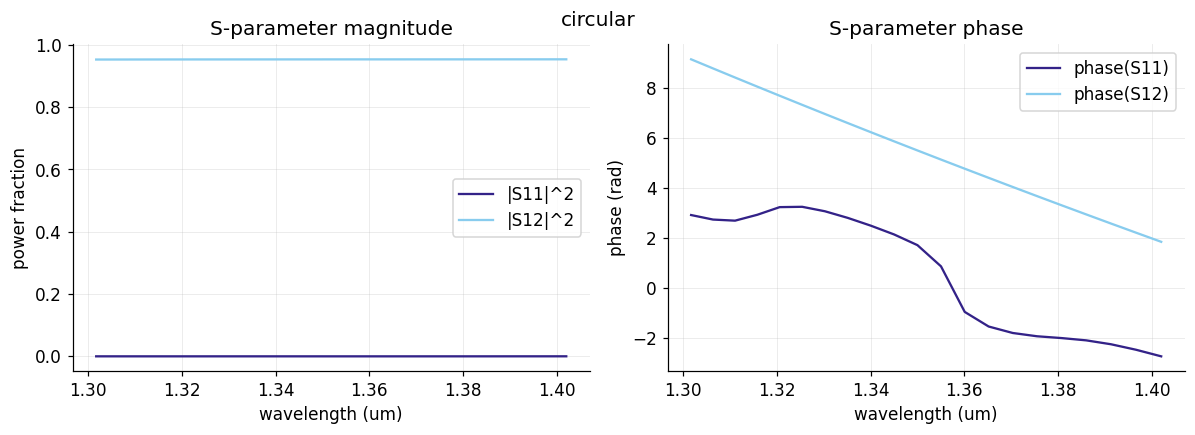

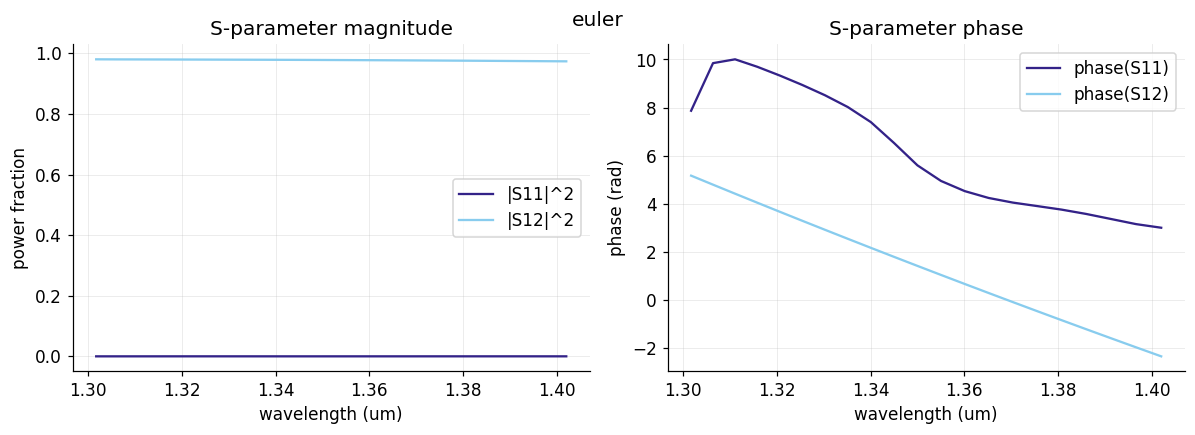

In [9]:
# Mid-band S11/S21 and insertion loss for both bend types, plus the full
# magnitude+phase spectra -- viz.plot_sparams applies this toolkit's shared
# color/style convention.
for bend_type in ["circular", "euler"]:
    r = results[bend_type]
    i_mid = len(r.wavelengths_um) // 2
    s11 = r.s_matrix["11"][i_mid]
    s21 = r.s_matrix["21"][i_mid]
    loss_db = -10 * np.log10(np.abs(s21) ** 2)
    print(f"{bend_type}: |S11|^2={np.abs(s11)**2:.4f}  |S21|^2={np.abs(s21)**2:.4f}  "
          f"insertion loss={loss_db:.3f} dB  (at wavelength={r.wavelengths_um[i_mid]:.4f} um)")

fig2 = viz.plot_sparams(results["circular"].wavelengths_um, results["circular"].s_matrix, pairs=("11", "12"))
fig2.suptitle("circular")
fig3 = viz.plot_sparams(results["euler"].wavelengths_um, results["euler"].s_matrix, pairs=("11", "12"))
fig3.suptitle("euler")
plt.show()


In [10]:
# Convert the representative-radius circular baseline into SAX's SDict
# convention -- the same shape models/bend.py's SAX model returns.
sdict = sparams.to_sdict(results["circular"].s_matrix, results["circular"].port_names)
print("SAX SDict keys (circular, representative radius):", list(sdict.keys()))


SAX SDict keys (circular, representative radius): [('o1', 'o1'), ('o1', 'o2'), ('o2', 'o1'), ('o2', 'o2')]


### 4.2b Radius sweep, both bend types (for Section 5's fit and the bending-loss plot)

**The baselines above have been inspected and validated -- only now do we
sweep.** `radius_um` swept in **0.25um steps from 1.0 to 3.0um** (9 points).
`sweep.grid_sweep()`'s Cartesian product over `{"radius_um": [...], "bend_type":
[...]}` runs all 18 combinations. Tolerances are loosened for the sweep to cover
`radius_um=1.0`'s expected higher loss.

In [11]:
# radius_um x bend_type Cartesian-product sweep: 9 radii x 2 bend types = 18
# independent FDTD baseline runs, one artifact (npz+json) each. Tolerances
# are loosened slightly relative to the single-radius baseline check, to
# cover radius_um=1.0's expected higher loss.
RADIUS_SWEEP_UM = [round(1.0 + 0.25 * i, 2) for i in range(9)]  # 1.0, 1.25, ..., 3.0
BEND_TYPES = ["circular", "euler"]

SWEEP_CHECK_KWARGS = {
    "energy_tol": 0.15, "reciprocity_tol": 0.15,
    "passivity_tol": 0.05, "max_loss_fraction": 0.5,
}

bend_rows = sweep.grid_sweep(
    simulate_fn=bend.simulate_baseline,
    base_params=params,
    param_grid={"radius_um": RADIUS_SWEEP_UM, "bend_type": BEND_TYPES},
    artifact_dir="../data/sparams/bend/sweep",
    component_name="bend",
    check_kwargs=SWEEP_CHECK_KWARGS,
    reuse_existing=True,  # reload a point whose artifact has the same geometry/resolution/tolerances
)
n_passed = sum(row["validation_passed"] for row in bend_rows)
print(f"radius x bend_type sweep: {n_passed}/{len(bend_rows)} points within the (loose) sweep tolerance")

manifest_path = "../data/sparams/bend/sweep/manifest.csv"
sweep.save_manifest(bend_rows, manifest_path)
print(f"Saved manifest to {manifest_path}")


[1/18  5%] running bend (radius_um=1.0, bend_type=circular) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[2/18  11%] running bend (radius_um=1.0, bend_type=euler) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[3/18  16%] running bend (radius_um=1.25, bend_type=circular) ...


...

[17/18  94%] running bend (radius_um=3.0, bend_type=circular) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[18/18  100%] running bend (radius_um=3.0, bend_type=euler) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


radius x bend_type sweep: 18/18 points within the (loose) sweep tolerance
Saved manifest to ../data/sparams/bend/sweep/manifest.csv


Reading sweep results at wavelength = 1.3500 um


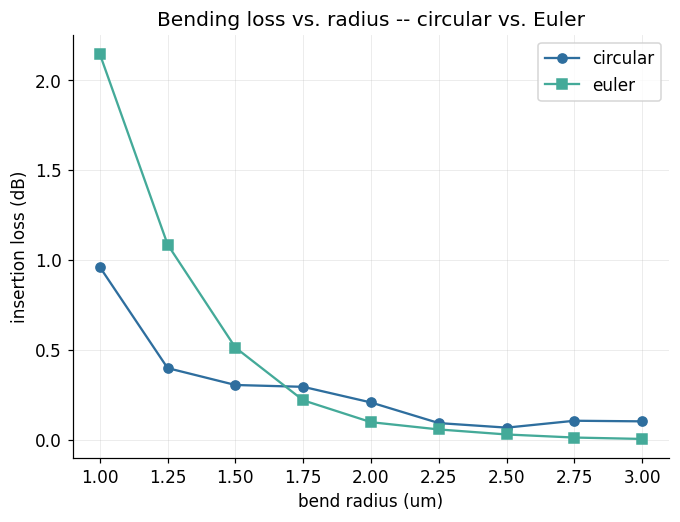

circular: loss_dB by radius = {1.0: np.float64(0.9606), 1.25: np.float64(0.3981), 1.5: np.float64(0.3041), 1.75: np.float64(0.2939), 2.0: np.float64(0.2068), 2.25: np.float64(0.0922), 2.5: np.float64(0.0669), 2.75: np.float64(0.1053), 3.0: np.float64(0.1019)}
euler: loss_dB by radius = {1.0: np.float64(2.1452), 1.25: np.float64(1.0853), 1.5: np.float64(0.5119), 1.75: np.float64(0.2188), 2.0: np.float64(0.0972), 2.25: np.float64(0.0569), 2.5: np.float64(0.0289), 2.75: np.float64(0.0118), 3.0: np.float64(0.0041)}


In [12]:
# Read insertion loss (dB) and phase back out of each swept artifact, at the
# same band-center wavelength used elsewhere, per bend type.
i_mid = len(results["circular"].wavelengths_um) // 2
wl0 = float(results["circular"].wavelengths_um[i_mid])
print(f"Reading sweep results at wavelength = {wl0:.4f} um")

loss_db_by_type = {}
phase_by_type = {}
for bend_type in BEND_TYPES:
    losses, phases = [], []
    for r in RADIUS_SWEEP_UM:
        a = sparams.load_artifact(f"../data/sparams/bend/sweep/bend_radius{r}_bend_type{bend_type}")
        s21 = a.s_matrix["21"][i_mid]
        losses.append(-10 * np.log10(np.abs(s21) ** 2))
        phases.append(np.angle(s21))
    loss_db_by_type[bend_type] = np.array(losses)
    phase_by_type[bend_type] = np.unwrap(np.array(phases))

fig, ax = plt.subplots(figsize=(7, 5))
for bend_type, color, marker in zip(BEND_TYPES, [style.COLOR_STEEL, style.COLOR_TEAL], ["o-", "s-"]):
    ax.plot(RADIUS_SWEEP_UM, loss_db_by_type[bend_type], marker, color=color, label=bend_type)
ax.set_xlabel("bend radius (um)")
ax.set_ylabel("insertion loss (dB)")
ax.set_title("Bending loss vs. radius -- circular vs. Euler")
ax.legend()
plt.show()

for bend_type in BEND_TYPES:
    print(f"{bend_type}: loss_dB by radius = "
          f"{dict(zip(RADIUS_SWEEP_UM, np.round(loss_db_by_type[bend_type], 4)))}")


**Reading this plot:** radiation loss should fall steeply as the radius grows. Where the
two bend types differ, the cause is the curvature profile: a circular bend jumps from
zero to $1/R$ curvature at each junction with the straight arms, which costs a
mode-mismatch (transition) loss, while an Euler bend ramps the curvature up smoothly.

**What the data shows** (loss at 1.35 µm):

- **Euler** falls monotonically, from 2.15 dB at `radius_um=1.0` to 0.004 dB at 3.0.
- **Circular** falls to about 0.1 dB by 2.25 µm and then stays there (0.092, 0.067,
  0.105, 0.102 dB at 2.25-3.0 µm). That floor is the transition loss at the two
  straight-to-arc junctions, which does not vanish with radius; its small oscillation
  with radius is consistent with interference between the two junctions' scattered
  fields, which changes with the arc length between them.
- **Euler is worse than circular from `radius_um=1.0` through 1.5** and better from
  1.75 onward (1.5 µm: Euler 0.512 dB vs. circular 0.304 dB; 1.75 µm: Euler 0.219 dB vs.
  circular 0.294 dB).

**Why Euler loses at small radius.** `bend_euler`'s default `with_arc_floorplan=True`
keeps the Euler bend's overall footprint the SAME as a circular bend of the given nominal
`radius` (confirmed via the bounding boxes printed in Section 2). To fit a smooth
curvature transition into that footprint, the Euler curve's peak curvature at its
midpoint must exceed `1/radius_um`, so at small radii "same nominal radius" does not
mean "never tighter than a circular arc of that radius." This notebook keeps
`with_arc_floorplan=True` (gdsfactory's default) because `build_gf_component`'s
coordinate-shift trick relies on it; comparing at equal *minimum* radius
(`with_arc_floorplan=False`) would need the port-alignment logic to read each
geometry's actual port positions, and is not done here.

**Result:** above ~1.75 µm the Euler bend is the lower-loss choice at a given footprint,
and its advantage grows with radius (0.004 vs. 0.10 dB at 3 µm), because it removes the
circular bend's junction loss.

## 5. SAX model fitting

`models/bend.py` fits insertion loss and phase, separately per bend type, from
the Section 4.2b sweep, so it can evaluate a bend of **any** radius, not just the
9 swept here -- the same generalization goal as the waveguide's cutback fit.

Loss vs. radius is visibly **not linear** (it falls steeply at small radius and
flattens toward a noise floor at large radius -- see the Section 4.2b plot), so
this notebook fits `loss_dB(r) = floor + amplitude * exp(-r / decay_um)` via
`scipy.optimize.curve_fit` instead of a straight line -- a shape that actually
matches bend physics (steep loss at tight radii, negligible loss once the bend
is gentle enough) and extrapolates sensibly to an untested radius (e.g. deciding
whether a `radius_um=3.5` bend is worth it). Phase stays a linear fit: it
accumulates with arc length, which is already linear in radius.

**The phase is fitted after removing the straight-guide propagation phase.** Between two
sweep radii 0.25 µm apart, the phase of $S_{21}$ advances by about
$\beta\,\pi\Delta R/2 \approx 4.4$ rad, more than π. `np.unwrap` of the raw phase
therefore cannot follow it and returns an aliased slope, one that is right only at the
sampled radii. The fit subtracts $\beta_0\pi R/2$ first ($\beta_0 = 2\pi
n_\mathrm{eff}/\lambda$ with $n_\mathrm{eff}$ from `waveguide.yaml`), unwraps and fits
the slowly varying remainder, and adds $\beta_0\pi/2$ back to the slope. The stored
`phase_slope` is then the true $d\phi/dR$.

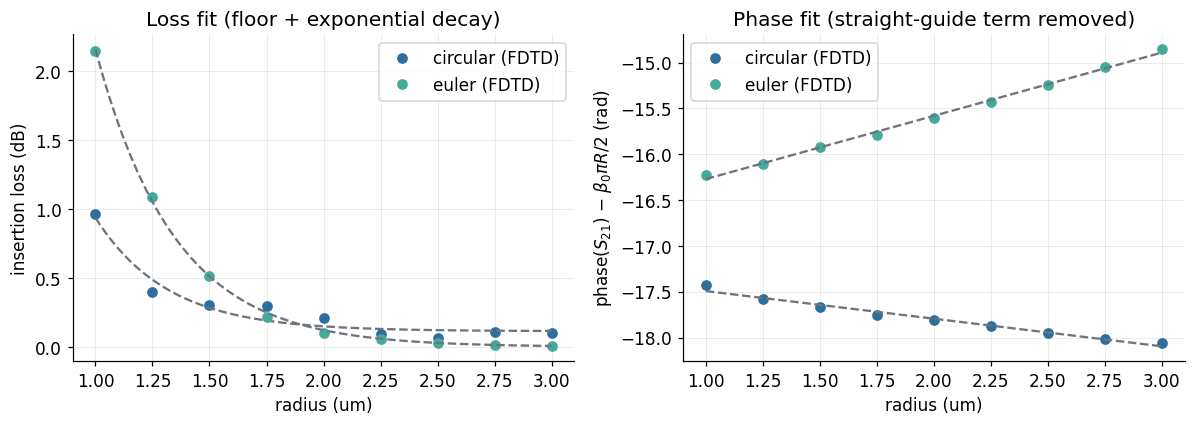

circular: {'loss_db_floor': 0.11422386648224399, 'loss_db_amplitude': 19.393222831522948, 'loss_db_decay_um': 0.31626913201689827, 'phase_slope': 17.63774120386805, 'phase_intercept': -17.19066845721152}
euler: {'loss_db_floor': 5.0732470876931296e-24, 'loss_db_amplitude': 38.26570396914751, 'loss_db_decay_um': 0.3477205698949754, 'phase_slope': 18.629124054361164, 'phase_intercept': -16.960565510267184}


In [13]:
# Straight-guide propagation constant, removed from the phase before unwrapping (see
# the markdown above: the raw phase advances by more than pi between sweep radii).
import yaml
with open("../data/design_points/waveguide.yaml") as f:
    beta0 = 2 * np.pi * yaml.safe_load(f)["fitted_model"]["n_eff"] / wl0

def _loss_model(r, floor, amplitude, decay_um):
    return floor + amplitude * np.exp(-r / decay_um)

fitted_model = {}
fig, (ax_loss, ax_phase) = plt.subplots(1, 2, figsize=(11, 4))
for bend_type, color in zip(BEND_TYPES, [style.COLOR_STEEL, style.COLOR_TEAL]):
    radii = np.array(RADIUS_SWEEP_UM, dtype=float)
    loss_db = loss_db_by_type[bend_type]

    # loss_db can dip a hair below 0 at the largest radii (S21 magnitude reading
    # very slightly above 1 from FDTD/discretization noise around a near-zero
    # true loss) -- clip the floor seed to stay within curve_fit's floor>=0
    # bound, since the model itself still allows fitting an exactly-zero floor.
    floor0 = max(loss_db.min(), 0.0)
    p0 = [floor0, loss_db.max() - floor0, 1.0]
    (floor, amplitude, decay_um), _ = curve_fit(
        _loss_model, radii, loss_db, p0=p0, bounds=([0, 0, 1e-3], [np.inf, np.inf, np.inf]),
    )
    slow_phase = np.unwrap(phase_by_type[bend_type] - beta0 * np.pi * radii / 2)
    phase_fit = np.polyfit(radii, slow_phase, 1)
    fitted_model[bend_type] = {
        "loss_db_floor": float(floor), "loss_db_amplitude": float(amplitude),
        "loss_db_decay_um": float(decay_um),
        "phase_slope": float(phase_fit[0] + beta0 * np.pi / 2), "phase_intercept": float(phase_fit[1]),
    }

    radii_fine = np.linspace(radii.min(), radii.max(), 200)
    ax_loss.plot(radii, loss_db, "o", color=color, label=f"{bend_type} (FDTD)")
    ax_loss.plot(radii_fine, _loss_model(radii_fine, floor, amplitude, decay_um), "--",
                 color=style.COLOR_REFERENCE)
    ax_phase.plot(radii, slow_phase, "o", color=color, label=f"{bend_type} (FDTD)")
    ax_phase.plot(radii, np.polyval(phase_fit, radii), "--", color=style.COLOR_REFERENCE)

ax_loss.set_xlabel("radius (um)"); ax_loss.set_ylabel("insertion loss (dB)")
ax_loss.set_title("Loss fit (floor + exponential decay)"); ax_loss.legend()
ax_phase.set_xlabel("radius (um)"); ax_phase.set_ylabel(r"phase($S_{21}$) $-\ \beta_0\pi R/2$ (rad)")
ax_phase.set_title("Phase fit (straight-guide term removed)"); ax_phase.legend()
fig.tight_layout()
plt.show()

for bend_type in BEND_TYPES:
    print(f"{bend_type}: {fitted_model[bend_type]}")

> **STOP -- inspect the fits before saving.**
>
> The loss fit (dashed) should hug the FDTD points' falling-then-flattening
> shape closely, not cut across them the way a straight line would. Euler's
> curve sits ABOVE circular's at small radius -- a real, physical
> `with_arc_floorplan` effect (see the markdown after the Section 4.2b plot),
> not noise -- so do not treat Euler as the better choice below
> `radius_um~1.5-1.75` (the measured crossover). The circular fit's floor
> (~0.11 dB) is the junction loss, and its small oscillation above 2.25 µm is not
> captured by the smooth fit.

## 6. Sanity checks

Run against the Section 4.1-4.2 **baseline** (representative radius) results for
both bend types. `ENERGY_TOL`/`RECIPROCITY_TOL`/`PASSIVITY_TOL` below are tuned to
this device's own measured power budget, with the TE/TM mode-selection convention
fixed throughout (Section 4.3); re-measure them before reusing this notebook as a
base for a new bend design.

In [14]:
# Run the shared 3-check validator against each bend type's representative-
# radius baseline, and hard-stop (assert) rather than continuing with an
# unvalidated result.
ENERGY_TOL = 0.08
RECIPROCITY_TOL = 0.10
PASSIVITY_TOL = 0.02
MAX_LOSS_FRACTION = 0.15

validations = {}
for bend_type in BEND_TYPES:
    v = checks.run_all_checks(
        results[bend_type].s_matrix,
        energy_tol=ENERGY_TOL, reciprocity_tol=RECIPROCITY_TOL,
        passivity_tol=PASSIVITY_TOL, max_loss_fraction=MAX_LOSS_FRACTION,
    )
    validations[bend_type] = v
    print(f"--- {bend_type} ---")
    print(json.dumps(v, indent=2))
    assert v["passed"], f"{bend_type} baseline failed sanity checks -- do not save or use this result."

print("\nBoth baselines validated.")


--- circular ---
{
  "energy_conservation": {
    "max_deviation_port1": 0.0,
    "max_deviation_port2": 0.0,
    "max_deviation": 0.0,
    "max_loss_fraction_allowed": 0.15,
    "tolerance": 0.08,
    "passed": true
  },
  "reciprocity": {
    "max_diff_s12_s21": 6.972444560257995e-06,
    "max_diff_s11_s22": 0.0005874560439960365,
    "max_diff": 0.0005874560439960365,
    "tolerance": 0.1,
    "passed": true
  },
  "passivity": {
    "max_magnitude": 0.9765801274323651,
    "tolerance": 0.02,
    "passed": true
  },
  "passed": true
}
--- euler ---
{
  "energy_conservation": {
    "max_deviation_port1": 0.0,
    "max_deviation_port2": 0.0,
    "max_deviation": 0.0,
    "max_loss_fraction_allowed": 0.15,
    "tolerance": 0.08,
    "passed": true
  },
  "reciprocity": {
    "max_diff_s12_s21": 7.357186774144499e-06,
    "max_diff_s11_s22": 0.0006160080382977945,
    "max_diff": 0.0006160080382977945,
    "tolerance": 0.1,
    "passed": true
  },
  "passivity": {
    "max_magnitude": 0

## 7. Save artifacts and design point

One `.npz`+`.json` artifact per bend type (same format as before), plus a
single design point recording `fitted_model` for **both** bend types (keyed
by name), so `models/bend.py` can select between them.

In [15]:
# One .npz+.json artifact per bend type, same format every other component
# uses -- artifact_stems collects both paths for the design-point save below.
artifact_stems = {}
for bend_type in BEND_TYPES:
    r = results[bend_type]
    artifact_stem = f"../data/sparams/bend/baseline/bend_baseline_{bend_type}"
    metadata = {
        "component": "bend",
        "geometry_params": {
            "radius_um": r.sim_params["radius_um"],
            "arm_length_um": r.sim_params["arm_length_um"],
            "wg_width_um": r.sim_params["wg_width_um"],
            "bend_type": bend_type,
        },
        "material_params": {
            "core_index": r.sim_params["core_index"],
            "clad_index": r.sim_params["clad_index"],
        },
        "polarization": f"TE ({r.field_snapshot.component} out-of-plane, confirmed dominant -- see Section 4.3)",
        "geometry_source": "gdsfactory (build_gf_component -> build_geometry_from_gds)",
        "meep_resolution": r.sim_params["resolution"],
        "simulation_params": {
            k: r.sim_params[k]
            for k in ["wl_min_um", "wl_max_um", "n_freq", "dpml_um", "margin_um",
                      "port_offset_um", "source_offset_um"]
        },
        "meep_version": r.sim_params["meep_version"],
        "python_version": r.sim_params["python_version"],
        "creation_date": r.sim_params["creation_date"],
        "validation": validations[bend_type],
    }
    sparams.save_artifact(
        artifact_stem, r.wavelengths_um, r.freqs,
        r.s_matrix, r.port_names, metadata,
    )
    artifact_stems[bend_type] = artifact_stem.replace("../", "")
    print(f"Saved artifact: {artifact_stem}.npz / .json")


Saved artifact: ../data/sparams/bend/baseline/bend_baseline_circular.npz / .json
Saved artifact: ../data/sparams/bend/baseline/bend_baseline_euler.npz / .json


In [16]:
# Single design point covering BOTH bend types (keyed by name in
# fitted_model), so models/bend.py can select between them at call time.
design_point_path = "../data/design_points/bend.yaml"

design_points.save_design_point(design_point_path, {
    "component": "bend",
    "parameters": {
        "radius_um": params["radius_um"],
        "arm_length_um": params["arm_length_um"],
        "wg_width_um": params["wg_width_um"],
        "core_index": params["core_index"],
        "clad_index": params["clad_index"],
        "bend_type": "circular",  # default selection for models.bend.bend() when unspecified
    },
    "source_artifacts": artifact_stems,
    "fitted_model": fitted_model,
    "provenance": {
        "method": "baseline_plus_radius_sweep_fit",
        "date": results["circular"].sim_params["creation_date"],
        "meep_version": results["circular"].sim_params["meep_version"],
    },
    "validation": validations,
    "rationale": (
        "Baseline geometry/S-parameters validated at radius_um=2.0 for both bend types "
        "(Sections 4.1-4.2, 6). Insertion loss fit as an exponential decay to a floor, "
        "and phase fit linearly, each against radius_um per bend type, from an independent "
        "radius_um=1.0-3.0um sweep (Section 4.2b/5), so the resulting analytic model "
        "generalizes to arbitrary radii for circuit-level (SAX) composition."
    ),
})
print(f"Saved design point: {design_point_path}")


Saved design point: ../data/design_points/bend.yaml


## 8. The bend SAX model

In [17]:
with open("../../src/pic_toolkit/models/bend.py") as f:
    print(f.read())

"""SAX-compatible component model for the 90-degree bent waveguide.

Architectural rule: this file NEVER imports meep, and NEVER launches an FDTD
simulation. It only reads the cached, validated `fitted_model` coefficients
that the Meep baseline notebook already fit per bend_type via a radius sweep
(loss_db as an exponential decay to a floor, phase linearly), via the design
point that stores them.
"""

from __future__ import annotations

from pathlib import Path

import numpy as np

from .. import design_points, sparams

_REPO_ROOT = Path(__file__).resolve().parents[3]
_DESIGN_POINT_PATH = _REPO_ROOT / "si" / "data" / "design_points" / "bend.yaml"

# gdsfactory's own bend components (see meep_sim/bend.py's build_gf_component)
# always name their two ports this way -- fixed here rather than read from
# the design point, since it's a property of the model, not data.
_PORT_NAMES = ("o1", "o2")


def bend(wl=1.35, radius_um: float | None = None, bend_type: str = "circular"):
    """SAX mode

---

## 9. The 2D bend against a calibrated Si strip and 3D results

The sweep above is exact for the 2D model (core 2.7). How does it compare with a real
500 × 220 nm strip? This section brings in two sets of runs from the SiN track
(`sin/notebooks/02_sin_bent_waveguide.ipynb`, §9), made with the same `meep_sim/bend.py`,
resolution and tolerances.

- **Si reference.** The 2D model with the n_eff-matched core 2.944
  (`params.SI_REF_PARAMS`). Its 2D mode has the real strip's $n_\mathrm{eff}$ (2.671 for
  Si 3.50), so it isolates the effect of the model's too-low index.
- **Benchmark.** The same calibration at the geometry of Bahadori et al.,
  *J. Lightwave Technol.* 37, 3044 (2019): a 400 × 220 nm strip at 1.55 µm, simulated
  there in 3D FDTD. This measures the error of the 2D model itself.


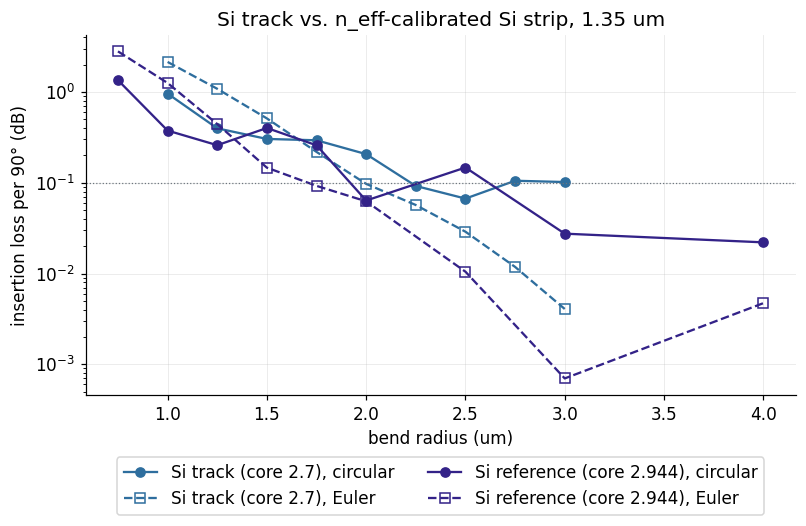

circular stays <= 0.1  dB from: Si track not reached   Si reference     2.62 um
euler    stays <= 0.1  dB from: Si track     1.99 um   Si reference     1.71 um
circular stays <= 0.01 dB from: Si track not reached   Si reference not reached
euler    stays <= 0.01 dB from: Si track     2.79 um   Si reference     2.51 um

2D (calibrated) vs. 3D FDTD, Bahadori et al. 2019, circular:
  R = 1.0 um: 2D 1.3790 dB, 3D fit 0.2916 dB, ratio 4.7
  R = 1.5 um: 2D 0.4272 dB, 3D fit 0.1162 dB, ratio 3.7
  R = 2.0 um: 2D 0.1923 dB, 3D fit 0.0611 dB, ratio 3.2
  R = 3.0 um: 2D 0.0645 dB, 3D fit 0.0250 dB, ratio 2.6
  R = 5.0 um: 2D 0.0230 dB, 3D fit 0.0084 dB, ratio 2.7


In [18]:
# Si track sweep (this notebook) vs. the calibrated Si reference, and the 2D-vs-3D benchmark.
SIN_SP = "../../sin/data/sparams"
SI_REF_RADII_UM = [0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 4.0]
si_ref_loss = {bt: np.array([-10 * np.log10(abs(sparams.load_artifact(
                   f"{SIN_SP}/si_ref_bend/sweep/si_ref_bend_radius{r}_bend_type{bt}").s_matrix["21"][i_mid]) ** 2)
                   for r in SI_REF_RADII_UM]) for bt in BEND_TYPES}

def radius_staying_below(radii, loss, target):
    # Smallest radius beyond which every swept point stays at or below the target
    # (log-linear interpolation); NaN if the sweep never settles below it.
    radii, loss = np.asarray(radii, float), np.asarray(loss, float)
    above = np.nonzero(loss > target)[0]
    if len(above) == 0 or above[-1] == len(loss) - 1:
        return np.nan
    i = above[-1] + 1
    t = (np.log(target) - np.log(loss[i - 1])) / (np.log(loss[i]) - np.log(loss[i - 1]))
    return float(radii[i - 1] + t * (radii[i] - radii[i - 1]))

fig, ax = plt.subplots(figsize=(7.5, 5))
for (label, rr, ll), color in zip([("Si track (core 2.7)", RADIUS_SWEEP_UM, loss_db_by_type),
                                   ("Si reference (core 2.944)", SI_REF_RADII_UM, si_ref_loss)],
                                  [style.COLOR_STEEL, style.COLOR_INDIGO]):
    ax.semilogy(rr, np.clip(ll["circular"], 1e-4, None), "o-", color=color, label=f"{label}, circular")
    ax.semilogy(rr, np.clip(ll["euler"], 1e-4, None), "s--", color=color, mfc="none", label=f"{label}, Euler")
ax.axhline(0.1, color=style.COLOR_REFERENCE, lw=0.8, ls=":")
ax.set_xlabel("bend radius (um)"); ax.set_ylabel("insertion loss per 90° (dB)")
ax.set_title("Si track vs. n_eff-calibrated Si strip, 1.35 um")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
plt.show()

fmt = lambda v: "not reached" if np.isnan(v) else f"{v:.2f} um"
for target in (0.1, 0.01):
    for bt in BEND_TYPES:
        a = radius_staying_below(RADIUS_SWEEP_UM, loss_db_by_type[bt], target)
        b = radius_staying_below(SI_REF_RADII_UM, si_ref_loss[bt], target)
        print(f"{bt:8s} stays <= {target:<4g} dB from: Si track {fmt(a):>11s}   Si reference {fmt(b):>11s}")

# 2D model vs. Bahadori's 3D FDTD fit (400 x 220 nm, 1.55 um), same calibration method.
bahadori = lambda R: 181.98 * R ** -2.49 * (np.pi * R / 2) * 1e-4 + 2 * 0.1315 * R ** -2.37
print("\n2D (calibrated) vs. 3D FDTD, Bahadori et al. 2019, circular:")
for R in (1.0, 1.5, 2.0, 3.0, 5.0):
    a = sparams.load_artifact(f"{SIN_SP}/benchmark/si_400x220_c_band/si_bahadori_bend_radius{R}_bend_typecircular")
    l2d = -10 * np.log10(abs(a.s_matrix["21"][len(a.wavelengths_um) // 2]) ** 2)
    print(f"  R = {R:3.1f} um: 2D {l2d:.4f} dB, 3D fit {bahadori(R):.4f} dB, ratio {l2d / bahadori(R):.1f}")


**Reading.**
- **Too-low index.** At the real strip's $n_\mathrm{eff}$, the Euler bend stays below
  0.1 dB from 1.71 µm and below 0.01 dB from 2.51 µm. The Si track needs about 2.0 µm and
  2.8 µm. The model's lower index therefore costs about 10–20 % in radius.
- **2D vs 3D.** Calibrated to the same $n_\mathrm{eff}$, the 2D model still loses 2.6–4.7×
  more than Bahadori's 3D FDTD fit, and 1.8× more than their directly simulated
  R = 5 µm bend. In radius, that is roughly 1.5× too large.
- **Combined.** The Si track's bend losses are *upper bounds* for a real oxide-clad
  500 × 220 nm strip. A real bend of the design radius (2 µm) loses less than the
  0.1–0.2 dB found here. The comparisons *within* the model still hold:
  - circular vs Euler;
  - the Euler crossover at about 1.5–1.75 µm;
  - the topology-optimized bend of notebook 04 against an Euler bend in the same
    footprint.
- **Ripple.** The circular curve is not monotonic: it dips at 2.5 µm and rises again to
  0.105 dB at 2.75 µm. The 2D strip guides TE1 (n_eff 1.65). The abrupt junctions of a
  circular bend couple TE0 into it, and the two beat along the arc. The predicted period
  in R is $2\lambda/(\pi\,\Delta n)$ = 1.11 µm. The Si reference shows the same ripple
  with its own period, 1.02 µm. The circular fit's 0.114 dB floor partly averages this
  ripple, so the circular SAX model is good to about ±0.04 dB above 2 µm.


---

## 10. Summary

Both bend geometries -- circular arc and Euler (clothoid) -- are now built
from a single gdsfactory `Component` per type, simulated across a
`radius_um=1.0-3.0um` sweep, and compared directly on bending loss (Section
4.2b's plot). A new `models/bend.py`, fit from that same sweep, generalizes
loss and phase to any radius. Section 9 places these losses against a calibrated
Si strip and 3D FDTD results: they are upper bounds for a real 500 × 220 nm strip (the
model's low index adds 10–20 % in radius, the 2D model itself about 1.5×). Continue to `03_mzi_arm.ipynb` (four bends as an MZI delay arm) or `04_bend_topology_optimization.ipynb`
for the next component.